# Phase 3: LSTM Model Training, Hyperparameter Tuning & Evaluation

**Project:** Agentic Predictive Maintenance  
**Dataset:** NASA C-MAPSS FD001  
**Objective:** Train an LSTM sequence regression model to predict Remaining Useful Life (RUL), conduct an engine-level cross-validation tuning grid with target normalization ($y / 125.0$) and early stopping on Validation MAE, evaluate on held-out test engines, and report MAE, RMSE, and NASA asymmetric score.

---
### Phase 3 Key Workflow:
1. **Engine-Level Train/Validation Split (80/20):** Prevent sequence overlap data leakage by splitting across engine units ($80$ train engines, $20$ validation engines).
2. **Target Normalization:** Normalize targets ($y / 125.0$) to balance gradient flow and prevent bias collapse.
3. **LSTM Neural Architecture (`src/model.py`):** Stacked LSTM with post-recurrent Dropout head for Phase 4 MC-Dropout compatibility.
4. **Hyperparameter Tuning Study (8 Configurations):** Sweep `hidden_size` $\in \{32, 64\}$, `dropout` $\in \{0.2, 0.3\}$, and `learning_rate` $\in \{0.001, 0.0005\}$.
5. **Early Stopping:** Monitored on **Validation MAE** (patience $= 8$, max epochs $= 60$).
6. **Final Test Evaluation (100 Engines):** Evaluate against true test ground truth (`RUL_FD001.txt`).
7. **NASA Asymmetric Scoring Function:** Compute penalty metric emphasizing safety against late failure overestimation.


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch.utils.data import TensorDataset, DataLoader

# Add project root to path
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "predictive-maintenance" else Path(".").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_cmapss
from src.preprocessing import (
    drop_uninformative_columns,
    compute_rul,
    scale_features,
    generate_sequences,
    get_test_sequences,
    get_engine_train_val_split,
    RETAINED_SENSOR_COLUMNS,
)
from src.model import LSTMRegressor
from src.train import (
    train_model,
    evaluate_model,
    compute_mae,
    compute_rmse,
    compute_nasa_score,
    scale_target,
    unscale_target,
    DEFAULT_TARGET_SCALE,
)

# Visual styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "eda_plots"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device} | PyTorch Version: {torch.__version__}")


Device: cpu | PyTorch Version: 2.13.0+cpu


## 1. Engine-Level Train/Validation Split
We partition the $100$ training engines into $80$ training units and $20$ validation units. Sequences are extracted separately to strictly prevent temporal sequence leakage.

In [2]:
train_df, test_df, rul_df = load_cmapss("FD001", data_dir=PROJECT_ROOT / "data" / "raw")
train_clean = drop_uninformative_columns(train_df)
test_clean = drop_uninformative_columns(test_df)
train_rul = compute_rul(train_clean, max_rul=125, is_train=True)
train_scaled, test_scaled, scaler = scale_features(train_rul, test_clean)

X_train_split, y_train_split, X_val_split, y_val_split, train_units, val_units = get_engine_train_val_split(
    train_scaled,
    val_ratio=0.2,
    sequence_length=30,
    feature_cols=RETAINED_SENSOR_COLUMNS,
    label_col="RUL_capped",
    seed=42,
)

X_test, test_unit_order = get_test_sequences(test_scaled, sequence_length=30)
y_test_raw = rul_df["RUL"].values.astype(np.float32)
y_test_capped = np.minimum(y_test_raw, 125.0).astype(np.float32)

# Target normalization
y_train_norm = scale_target(y_train_split, DEFAULT_TARGET_SCALE)
y_val_norm = scale_target(y_val_split, DEFAULT_TARGET_SCALE)

print(f"Train Split: {len(train_units)} engines -> X_train: {X_train_split.shape}, y_train: {y_train_split.shape}")
print(f"Val Split:   {len(val_units)} engines -> X_val:   {X_val_split.shape}, y_val:   {y_val_split.shape}")
print(f"Test Set:    100 engines -> X_test:  {X_test.shape}, y_test:  {y_test_raw.shape}")


Train Split: 80 engines -> X_train: (14459, 30, 14), y_train: (14459,)
Val Split:   20 engines -> X_val:   (3272, 30, 14), y_val:   (3272,)
Test Set:    100 engines -> X_test:  (100, 30, 14), y_test:  (100,)


## 2. PyTorch DataLoaders

In [3]:
batch_size = 64
train_dataset = TensorDataset(torch.tensor(X_train_split, dtype=torch.float32), torch.tensor(y_train_norm, dtype=torch.float32))
val_dataset = TensorDataset(torch.tensor(X_val_split, dtype=torch.float32), torch.tensor(y_val_norm, dtype=torch.float32))
test_dataset = TensorDataset(torch.tensor(X_test, dtype=torch.float32), torch.tensor(y_test_capped, dtype=torch.float32))

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)
print("DataLoaders ready.")


DataLoaders ready.


## 3. Compact Hyperparameter Tuning Grid (8 Runs)
We sweep combinations of:
* `hidden_size`: $32, 64$
* `dropout`: $0.2, 0.3$
* `learning_rate`: $0.001, 0.0005$
* Early stopping: monitored on **Validation MAE** with patience $= 8$.

In [4]:
grid = [
    {"hidden_size": 32, "dropout": 0.2, "learning_rate": 0.0010},
    {"hidden_size": 32, "dropout": 0.2, "learning_rate": 0.0005},
    {"hidden_size": 32, "dropout": 0.3, "learning_rate": 0.0010},
    {"hidden_size": 32, "dropout": 0.3, "learning_rate": 0.0005},
    {"hidden_size": 64, "dropout": 0.2, "learning_rate": 0.0010},
    {"hidden_size": 64, "dropout": 0.2, "learning_rate": 0.0005},
    {"hidden_size": 64, "dropout": 0.3, "learning_rate": 0.0010},
    {"hidden_size": 64, "dropout": 0.3, "learning_rate": 0.0005},
]

tuning_records = []
models_dict = {}

max_epochs = 60
patience = 8

for i, cfg in enumerate(grid, 1):
    torch.manual_seed(42)
    model = LSTMRegressor(
        input_size=14,
        hidden_size=cfg["hidden_size"],
        num_layers=2,
        dropout_rate=cfg["dropout"],
    )

    trained_model, history = train_model(
        model,
        train_loader,
        val_loader,
        epochs=max_epochs,
        lr=cfg["learning_rate"],
        patience=patience,
        target_scale=DEFAULT_TARGET_SCALE,
        device=device,
        verbose=False,
    )

    val_preds, val_targets, val_metrics = evaluate_model(
        trained_model, val_loader, target_scale=DEFAULT_TARGET_SCALE, device=device
    )

    best_ep = history["best_epoch"]
    tot_ep = history["epochs_trained"]
    near_max = best_ep >= (max_epochs - 3)

    record = {
        "config_id": i,
        "hidden_size": cfg["hidden_size"],
        "dropout": cfg["dropout"],
        "learning_rate": cfg["learning_rate"],
        "val_MAE": round(val_metrics["MAE"], 4),
        "val_RMSE": round(val_metrics["RMSE"], 4),
        "val_NASA_Score": round(val_metrics["NASA_Score"], 2),
        "epochs_trained": tot_ep,
        "best_epoch": best_ep,
        "near_max_flag": near_max,
    }
    tuning_records.append(record)
    models_dict[i] = (trained_model, history, val_metrics)

tuning_df = pd.DataFrame(tuning_records).sort_values(by="val_MAE").reset_index(drop=True)
tuning_df.to_csv(PROJECT_ROOT / "outputs" / "tuning_results.csv", index=False)
tuning_df


,config_id,hidden_size,dropout,learning_rate,val_MAE,val_RMSE,val_NASA_Score,epochs_trained,best_epoch,near_max_flag
0,5,64,0.2,0.0010,8.7577,12.8300,10407.40,43,35,False
1,1,32,0.2,0.0010,8.8951,12.8328,10107.40,33,25,False
2,8,64,0.3,0.0005,8.9019,12.9555,10913.53,43,35,False
3,6,64,0.2,0.0005,8.9715,13.0672,11228.39,43,35,False
4,7,64,0.3,0.0010,8.9729,12.9526,10653.80,43,35,False
5,3,32,0.3,0.0010,9.0749,12.9529,10300.03,33,25,False
6,4,32,0.3,0.0005,9.4151,13.6035,12043.31,29,21,False
7,2,32,0.2,0.0005,9.4732,13.6603,12345.38,29,21,False


## 4. Best Model Selection & Checkpointing
We select the model configuration achieving the minimum **Validation MAE** (no test data used for selection).

In [5]:
best_row = tuning_df.iloc[0]
best_config_id = int(best_row["config_id"])
best_model, best_history, best_val_metrics = models_dict[best_config_id]

print(f"Selected Best Configuration (#{best_config_id}):")
print(f"  • Hidden Units:   {int(best_row['hidden_size'])}")
print(f"  • Dropout:        {best_row['dropout']}")
print(f"  • Learning Rate:  {best_row['learning_rate']}")
print(f"  • Validation MAE: {best_row['val_MAE']:.4f} cycles")
print(f"  • Validation RMSE:{best_row['val_RMSE']:.4f} cycles")
print(f"  • Best Epoch:     {int(best_row['best_epoch'])} / {int(best_row['epochs_trained'])}")

# Save model checkpoint with target_scale=125.0
torch.save(
    {
        "model_state_dict": best_model.state_dict(),
        "config": {
            "input_size": 14,
            "hidden_size": int(best_row["hidden_size"]),
            "num_layers": 2,
            "dropout_rate": float(best_row["dropout"]),
            "sequence_length": 30,
            "target_scale": DEFAULT_TARGET_SCALE,
        },
    },
    PROJECT_ROOT / "outputs" / "best_lstm_model.pt",
)
print("Saved winning model to outputs/best_lstm_model.pt")


Selected Best Configuration (#5):
  • Hidden Units:   64
  • Dropout:        0.2
  • Learning Rate:  0.001
  • Validation MAE: 8.7577 cycles
  • Validation RMSE:12.8300 cycles
  • Best Epoch:     35 / 43
Saved winning model to outputs/best_lstm_model.pt


## 5. Final Evaluation on Held-Out Test Set (100 Engines)
Evaluated ONCE on the held-out test set against both capped target ($RUL \le 125$) and raw ground-truth ($RUL$).

In [6]:
test_preds, _, _ = evaluate_model(
    best_model, test_loader, target_scale=DEFAULT_TARGET_SCALE, device=device
)

test_mae_capped = compute_mae(y_test_capped, test_preds)
test_rmse_capped = compute_rmse(y_test_capped, test_preds)
test_nasa_capped = compute_nasa_score(y_test_capped, test_preds)

test_mae_raw = compute_mae(y_test_raw, test_preds)
test_rmse_raw = compute_rmse(y_test_raw, test_preds)
test_nasa_raw = compute_nasa_score(y_test_raw, test_preds)

eval_summary = pd.DataFrame([
    {"Target": "Capped RUL (max=125)", "MAE": test_mae_capped, "RMSE": test_rmse_capped, "NASA Score": test_nasa_capped},
    {"Target": "Raw True RUL", "MAE": test_mae_raw, "RMSE": test_rmse_raw, "NASA Score": test_nasa_raw},
])
eval_summary


,Target,MAE,RMSE,NASA Score
0,Capped RUL (max=125),10.200366,13.898388,307.871265
1,Raw True RUL,11.270367,15.381811,364.810065


## 6. Evaluation Visualizations

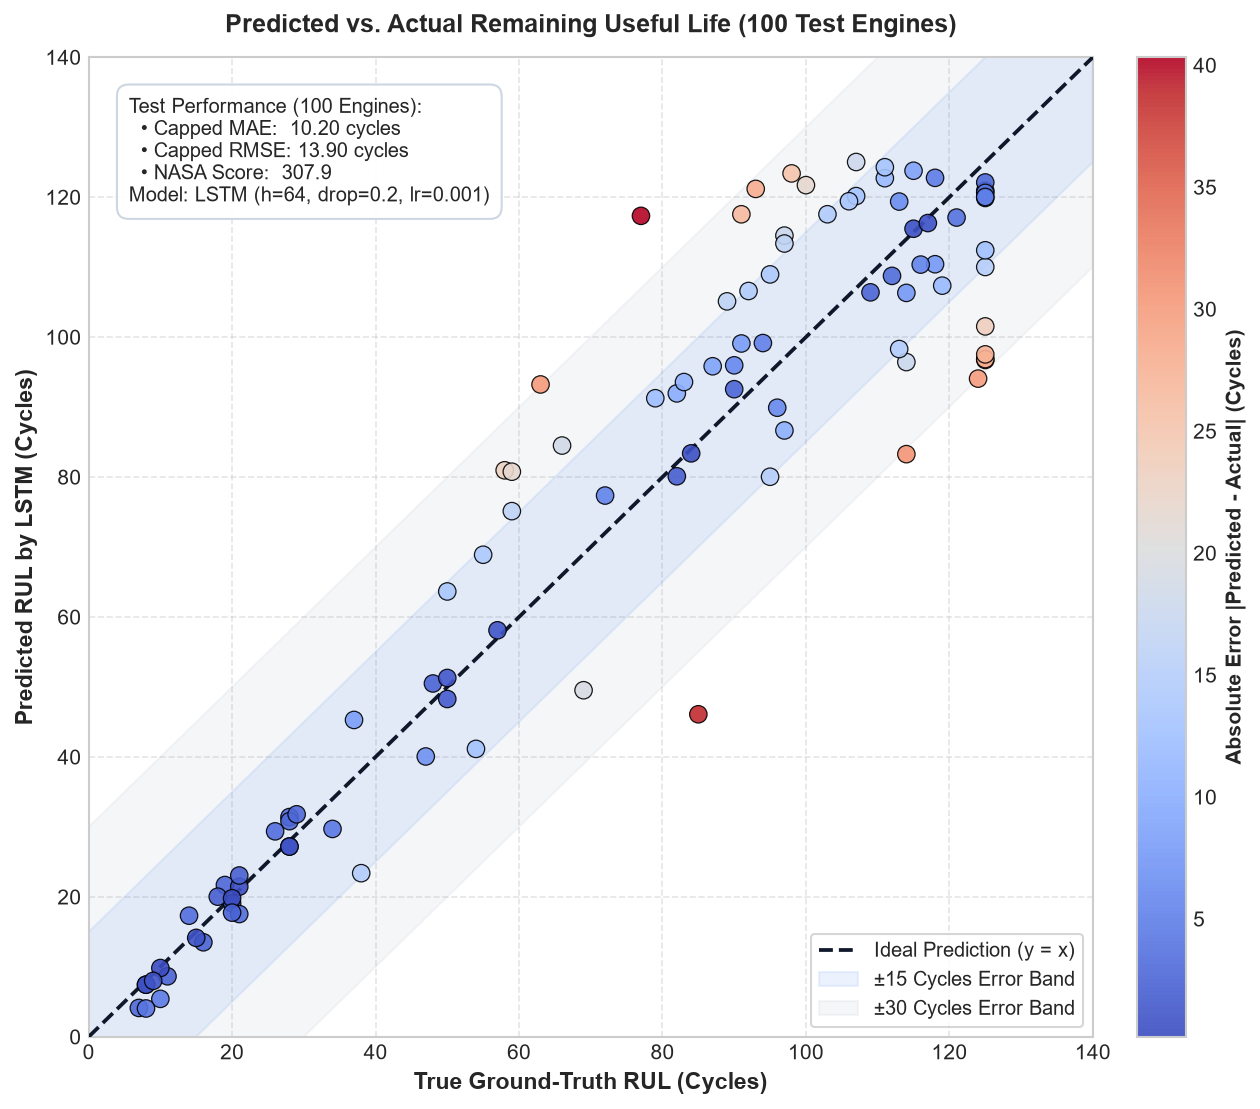

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 7.5), dpi=150)
errors = test_preds - y_test_capped

scatter = ax.scatter(
    y_test_capped,
    test_preds,
    c=np.abs(errors),
    cmap="coolwarm",
    s=70,
    edgecolor="black",
    linewidth=0.6,
    alpha=0.9,
    zorder=4,
)
cbar = plt.colorbar(scatter, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Absolute Error |Predicted - Actual| (Cycles)", fontsize=10, fontweight="bold")

lims = [0, 140]
ax.plot(lims, lims, color="#0f172a", linestyle="--", linewidth=1.8, label="Ideal Prediction (y = x)", zorder=3)
ax.fill_between(lims, [l - 15 for l in lims], [l + 15 for l in lims], color="#3b82f6", alpha=0.10, label="±15 Cycles Error Band")
ax.fill_between(lims, [l - 30 for l in lims], [l + 30 for l in lims], color="#64748b", alpha=0.06, label="±30 Cycles Error Band")

metric_text = (
    f"Test Performance (100 Engines):\n"
    f"  • Capped MAE:  {test_mae_capped:.2f} cycles\n"
    f"  • Capped RMSE: {test_rmse_capped:.2f} cycles\n"
    f"  • NASA Score:  {test_nasa_capped:.1f}\n"
    f"Model: LSTM (h={int(best_row['hidden_size'])}, drop={best_row['dropout']}, lr={best_row['learning_rate']})"
)
ax.text(
    0.04, 0.96, metric_text, transform=ax.transAxes, fontsize=9.5, verticalalignment="top",
    bbox=dict(boxstyle="round,pad=0.6", facecolor="white", edgecolor="#cbd5e1", alpha=0.95), zorder=5
)

ax.set_xlim(0, 140)
ax.set_ylim(0, 140)
ax.set_xlabel("True Ground-Truth RUL (Cycles)", fontsize=11, fontweight="bold")
ax.set_ylabel("Predicted RUL by LSTM (Cycles)", fontsize=11, fontweight="bold")
ax.set_title("Predicted vs. Actual Remaining Useful Life (100 Test Engines)", fontsize=12, fontweight="bold", pad=12)
ax.legend(loc="lower right", frameon=True, fontsize=9.5)
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()
